## Olist E-Commerce: Data Exploration with DuckDB

## 1. Setup the notebook

In this notebook we load five tables of the e-commerce dataset into DuckDB and explore them with SQL before designing a data warehouse.

**What we will do**

1. Load the CSV files into DuckDB
2. Understand each table: structure, grain, keys
3. Check the relationships (foreign keys)
4. Find data quality issues
5. Build a star schema

**Tables:** `customers`, `orders`, `order_items`, `products`, `sellers`

In [25]:
from pathlib import Path

import duckdb
import pandas as pd
import matplotlib.pyplot as plt

In [26]:
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
WAREHOUSE_DIR = DATA_DIR / "warehouse"
csv = RAW_DIR / "olist_orders_dataset.csv"

In [27]:
print(duckdb.sql(f"SELECT count(*) FROM '{csv}'"))

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│        99441 │
└──────────────┘



### DuckDB lets query CSV data with SQL. The database file persists locally so later notebooks can reuse the loaded raw tables.

In [28]:
DB_PATH = WAREHOUSE_DIR / "ecommerce.duckdb"

# Ensure the warehouse directory exists before connecting
WAREHOUSE_DIR.mkdir(parents=True, exist_ok=True)

con = duckdb.connect(str(DB_PATH))


In [29]:
def q(sql_str: str) -> pd.DataFrame:
    """Run a SQL query in DuckDB and return a pandas DataFrame."""
    return con.sql(sql_str).df()

## 2. Load the source tables into a **raw schema**

A Schema is a namespace that groups tables. We keep the source copies in **raw**
so that they remain distinguishable from cleaned warehouse tables we will create later.

### Define a mapping to transform column types

In [30]:
RAW_TABLES: dict[str, dict[str, str]] = {
    "customers": {"customer_zip_code_prefix": "VARCHAR"},  # keep leading zeros
    "orders": {},
    "order_items": {},
    "products": {},
    "sellers": {}
}

### Define some helper functions

In [31]:
def csv_path(table: str) -> Path:
    """"""
    return RAW_DIR / f"olist_{table}_dataset.csv"

def check_source_files(tables) -> None:
    """Fail once, list every missing file"""
    missing = [csv_path(t) for t in tables if not csv_path(t).exists()]
    if missing:
        names = "\n".join(f" - {p}" for p in missing)
        raise FileNotFoundError(f"Missing CSV files: {names}")

#### Define schema name for source data

In [32]:
RAW_SCHEMA = "raw"

### Load data into source tables

In [36]:
def load_raw_table(con: duckdb.DuckDBPyConnection, table: str, column_types: dict[str, str]) -> int:
    target = f'{RAW_SCHEMA}."{table}"'
    source = con.read_csv(str(csv_path(table)), header=True, dtype=column_types or None)
    con.execute(f"DROP TABLE IF EXISTS {target}")
    source.to_table(target)
    return con.execute(f"SELECT count(*) FROM {target}").fetchone()[0]

### Sanity check if we have all required source files

In [37]:
check_source_files(RAW_TABLES)

### Create **RAW_SCHEMA** if it does not exist

In [38]:
con.execute(f"CREATE SCHEMA IF NOT EXISTS {RAW_SCHEMA}")

### Execute **load_raw_table** to load all source data

In [39]:
row_counts = {t: load_raw_table(con, t, types) for t, types in RAW_TABLES.items()}

### Check count of rows inserted into each `raw`.`<table>`

In [40]:
pd.DataFrame(row_counts.items(), columns=["table_name", "row_count"])

,table_name,row_count
0,customers,99441
1,orders,99441
2,order_items,112650
3,products,32951
4,sellers,3095


## 3. Look at each table

For every table we ask: **what does one row represent?** This is the *grain*. Getting the grain right is the most important step in dimensional modeling.

In [41]:
for t in RAW_TABLES:
    print(f"----- {t} -----")
    display(q(f"DESCRIBE raw.{t}")[["column_name", "column_type", "null"]])
    display(q(f"SELECT * FROM raw.{t} LIMIT 3"))

----- customers -----


,column_name,column_type,null
0,customer_id,VARCHAR,YES
1,customer_unique_id,VARCHAR,YES
2,customer_zip_code_prefix,VARCHAR,YES
3,customer_city,VARCHAR,YES
4,customer_state,VARCHAR,YES


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP


----- orders -----


,column_name,column_type,null
0,order_id,VARCHAR,YES
1,customer_id,VARCHAR,YES
2,order_status,VARCHAR,YES
3,order_purchase_timestamp,TIMESTAMP,YES
4,order_approved_at,TIMESTAMP,YES
5,order_delivered_carrier_date,TIMESTAMP,YES
6,order_delivered_customer_date,TIMESTAMP,YES
7,order_estimated_delivery_date,TIMESTAMP,YES


...

,column_name,column_type,null
0,product_id,VARCHAR,YES
1,product_category_name,VARCHAR,YES
2,product_name_lenght,BIGINT,YES
3,product_description_lenght,BIGINT,YES
4,product_photos_qty,BIGINT,YES
5,product_weight_g,BIGINT,YES
6,product_length_cm,BIGINT,YES
7,product_height_cm,BIGINT,YES
8,product_width_cm,BIGINT,YES


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40,287,1,225,16,10,14
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44,276,1,1000,30,18,20
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46,250,1,154,18,9,15


----- sellers -----


,column_name,column_type,null
0,seller_id,VARCHAR,YES
1,seller_zip_code_prefix,VARCHAR,YES
2,seller_city,VARCHAR,YES
3,seller_state,VARCHAR,YES


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ


`SUMMARIZE`profiles every column is one command: min, max, average, null percentage,
approximate distinct count.

In [42]:
q("SUMMARIZE raw.order_items")

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,order_id,VARCHAR,00010242fe8c5a6d1ba2dd792cb16214,fffe41c64501cc87c801fd61db3f6244,87618,NaN,NaN,NaN,NaN,NaN,112650,0.0
1,order_item_id,BIGINT,1,21,21,1.1978339991122948,0.7051240313951734,1,1,1,112650,0.0
2,product_id,VARCHAR,00066f42aeeb9f3007548bb9d3f33c38,fffe9eeff12fcbd74a2f2b007dde0c58,24292,NaN,NaN,NaN,NaN,NaN,112650,0.0
3,seller_id,VARCHAR,0015a82c2db000af6aaaf3ae2ecb0532,ffff564a4f9085cd26170f4732393726,3886,NaN,NaN,NaN,NaN,NaN,112650,0.0
4,shipping_limit_date,TIMESTAMP,2016-09-19 00:15:34,2020-04-09 22:35:08,80774,2018-01-07 15:36:52.192685,NaN,2017-09-20 14:24:06.919554,2018-01-27 19:47:01.503972,2018-05-11 00:22:53.928243,112650,0.0
5,price,DOUBLE,0.85,6735.0,6497,120.65373901477311,183.6339280502597,40.01666999532123,74.5760959518914,134.19097071958893,112650,0.0
6,freight_value,DOUBLE,0.0,409.68,5665,19.99031992898562,15.806405412296998,13.071531156591233,16.279508106244663,21.16306476327699,112650,0.0


In [43]:
q("SUMMARIZE raw.order_items")

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,order_id,VARCHAR,00010242fe8c5a6d1ba2dd792cb16214,fffe41c64501cc87c801fd61db3f6244,87618,NaN,NaN,NaN,NaN,NaN,112650,0.0
1,order_item_id,BIGINT,1,21,21,1.1978339991122948,0.7051240313951734,1,1,1,112650,0.0
2,product_id,VARCHAR,00066f42aeeb9f3007548bb9d3f33c38,fffe9eeff12fcbd74a2f2b007dde0c58,24292,NaN,NaN,NaN,NaN,NaN,112650,0.0
3,seller_id,VARCHAR,0015a82c2db000af6aaaf3ae2ecb0532,ffff564a4f9085cd26170f4732393726,3886,NaN,NaN,NaN,NaN,NaN,112650,0.0
4,shipping_limit_date,TIMESTAMP,2016-09-19 00:15:34,2020-04-09 22:35:08,80774,2018-01-07 15:36:52.192685,NaN,2017-09-20 14:24:06.919554,2018-01-27 19:47:01.503972,2018-05-11 00:22:53.928243,112650,0.0
5,price,DOUBLE,0.85,6735.0,6497,120.65373901477311,183.6339280502597,40.01666999532123,74.5760959518914,134.19097071958893,112650,0.0
6,freight_value,DOUBLE,0.0,409.68,5665,19.99031992898562,15.806405412296998,13.071531156591233,16.279508106244663,21.16306476327699,112650,0.0


In [44]:
q("SUMMARIZE raw.products")

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,product_id,VARCHAR,00066f42aeeb9f3007548bb9d3f33c38,fffe9eeff12fcbd74a2f2b007dde0c58,24292,NaN,NaN,NaN,NaN,NaN,32951,0.00
1,product_category_name,VARCHAR,agro_industria_e_comercio,utilidades_domesticas,66,NaN,NaN,NaN,NaN,NaN,32951,1.85
2,product_name_lenght,BIGINT,5,76,64,48.47694876472589,10.245740725237287,42,51,57,32951,1.85
3,product_description_lenght,BIGINT,4,3992,2781,771.4952846232337,635.1152246349538,339,594,973,32951,1.85
4,product_photos_qty,BIGINT,1,20,20,2.1889861166939797,1.7367656379315435,1,1,3,32951,1.85
5,product_weight_g,BIGINT,0,40425,2155,2276.4724877841513,4282.038730977024,300,701,1883,32951,0.01
6,product_length_cm,BIGINT,7,105,97,30.81507784758263,16.914458054065953,18,25,39,32951,0.01
7,product_height_cm,BIGINT,2,105,99,16.937661234028347,13.637554061749569,8,13,21,32951,0.01
8,product_width_cm,BIGINT,6,118,92,23.196728277034204,12.079047453227794,15,20,30,32951,0.01


## 4. Primary Keys

A **primary key** uniquely identifies a row. A column is a valid candidate only if `count(*) = count(distinct ...)` and it has no nulls.

- A **composite key** uses several columns together (`order_items`)
- A **natural key** comes from the business (`customer_unique_id`).
- A **surrogate key** is generated by the warehouse (`customer_key = 1, 2, 3...`)

In [45]:
q("""
SELECT 'customers.customer_id'         AS candidate, count(*) AS n, count(DISTINCT customer_id) AS n_distinct FROM raw.customers
UNION ALL SELECT 'customers.customer_unique_id',         count(*), count(DISTINCT customer_unique_id) FROM raw.customers
UNION ALL SELECT 'orders.order_id',                      count(*), count(DISTINCT order_id) FROM raw.orders
UNION ALL SELECT 'order_items.order_id (alone)',         count(*), count(DISTINCT order_id) FROM raw.order_items
UNION ALL SELECT 'order_items(order_id, order_item_id)', count(*), count(DISTINCT (order_id, order_item_id)) FROM raw.order_items
UNION ALL SELECT 'products.product_id',                  count(*), count(DISTINCT product_id) FROM raw.products
UNION ALL SELECT 'sellers.seller_id',                    count(*), count(DISTINCT seller_id) FROM raw.sellers
""")

,candidate,n,n_distinct
0,customers.customer_id,99441,99441
1,customers.customer_unique_id,99441,96096
2,orders.order_id,99441,99441
3,order_items.order_id (alone),112650,98666
4,"order_items(order_id, order_item_id)",112650,112650
5,products.product_id,32951,32951
6,sellers.seller_id,3095,3095


## 4. Foreign key relationships

```
customers 1 ---- N orders 1 ---- N order_items N ---- 1 products
```

A foreign key is healthy when every value exists in the parent table. An **orphan** is
a child row with no parent.

In [46]:
q("""
SELECT 'orders without customer' AS check_name, count(*) AS n
  FROM raw.orders o ANTI JOIN raw.customers c USING (customer_id)
UNION ALL SELECT 'items without order', count(*)
  FROM raw.order_items i ANTI JOIN raw.orders o USING (order_id)
UNION ALL SELECT 'items without product', count(*)
  FROM raw.order_items i ANTI JOIN raw.products p USING (product_id)
UNION ALL SELECT 'items without seller', count(*)
    FROM raw.order_items i ANTI JOIN raw.sellers s USING (seller_id)
UNION ALL SELECT 'orders without items', count(*)
  FROM raw.orders o ANTI JOIN raw.order_items i USING (order_id)
""")

,check_name,n
0,orders without customer,0
1,items without order,0
2,items without product,0
3,items without seller,0
4,orders without items,775


No orphans in the child-to-parent direction. But 775 orders have no items. An **INNER JOIN** from orders
to items would silently remove them.

## 5. Data Quality

we check five dimensions: completeness(nulls), uniqueness, validity (values in a sensible range),
consistency (fields agree), timeliness (coverage)

### 5.1 Orders with no items

#### Exercise 1

In [47]:
q("""
SELECT 
    o.order_status, 
    count(*) AS orders_without_items
FROM raw.orders o
ANTI JOIN raw.order_items i USING (order_id)
GROUP BY o.order_status
ORDER BY orders_without_items DESC;
""")

,order_status,orders_without_items
0,unavailable,603
1,canceled,164
2,created,5
3,invoiced,2
4,shipped,1


### 5.2 Check order status and class imbalance

#### Exercise 2

In [48]:
q("""
SELECT 
    order_status, 
    count(*) AS n, 
    round(count(*) * 100.0 / (SELECT count(*) FROM raw.orders), 2) AS pct
FROM raw.orders
GROUP BY order_status
ORDER BY n DESC;
""")

,order_status,n,pct
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


### 5.3 Missing and inconsistent timestamps

#### Exercise 3

In [49]:
q("""
SELECT 
    count(CASE WHEN order_approved_at IS NULL THEN 1 END) AS approved_null,
    count(CASE WHEN order_delivered_carrier_date IS NULL THEN 1 END) AS carrier_null,
    count(CASE WHEN order_delivered_customer_date IS NULL THEN 1 END) AS delivered_null,
    count(CASE WHEN order_status = 'delivered' AND order_delivered_customer_date IS NULL THEN 1 END) AS delivered_but_no_date,
    count(CASE WHEN order_delivered_carrier_date > order_delivered_customer_date THEN 1 END) AS carrier_after_customer
FROM raw.orders;
""")

,approved_null,carrier_null,delivered_null,delivered_but_no_date,carrier_after_customer
0,160,1783,2965,8,23


### 5.4 Time coverage

#### Exercise 4

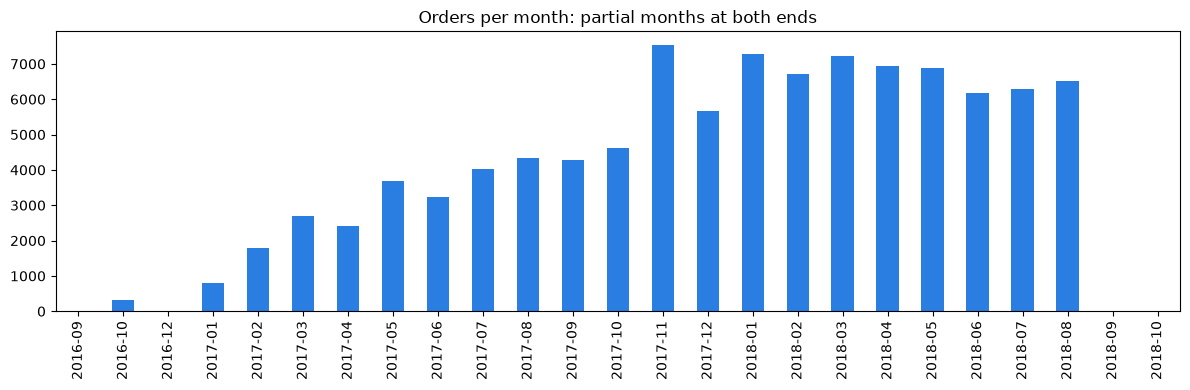

In [50]:
monthly = q("""
SELECT 
    strftime(order_purchase_timestamp, '%Y-%m') AS month,
    count(*) AS orders
FROM raw.orders
GROUP BY month
ORDER BY month;
""")
ax = monthly.plot.bar(x="month", y="orders", figsize=(12, 4), legend=False, color="#2a7de1")
ax.set_title("Orders per month: partial months at both ends")
ax.set_xlabel("")
plt.tight_layout(); plt.show()

### 5.5 Product completeness check

#### Exercise 5

In [52]:
q("""
SELECT 
    count(*) AS products,
    count(CASE WHEN product_category_name IS NULL THEN 1 END) AS category_null,
    count(CASE WHEN product_weight_g IS NULL THEN 1 END) AS weight_null,
    count(CASE WHEN product_weight_g = 0 THEN 1 END) AS weight_zero,
    count(DISTINCT product_category_name) AS n_categories
FROM raw.products;
""")

,products,category_null,weight_null,weight_zero,n_categories
0,32951,610,2,4,73


```mermaid
erDiagram
    CUSTOMERS ||--o{ ORDERS : places
    ORDERS ||--o{ ORDER_ITEMS : contains
    PRODUCTS ||--o{ ORDER_ITEMS : ordered_in
    SELLERS ||--o{ ORDER_ITEMS : fulfills

    CUSTOMERS {
        string customer_id PK
        string customer_unique_id
        string customer_zip_code_prefix
        string customer_city
        string customer_state
    }

    ORDERS {
        string order_id PK
        string customer_id FK
        string order_status
        timestamp order_purchase_timestamp
        timestamp order_approved_at
        timestamp order_delivered_carrier_date
        timestamp order_delivered_customer_date
        timestamp order_estimated_delivery_date
    }

    ORDER_ITEMS {
        string order_id PK, FK
        int order_item_id PK
        string product_id FK
        string seller_id FK
        timestamp shipping_limit_date
        decimal price
        decimal freight_value
    }

    PRODUCTS {
        string product_id PK
        string product_category_name
        int product_name_lenght
        int product_description_lenght
        int product_photos_qty
        int product_weight_g
        int product_length_cm
        int product_height_cm
        int product_width_cm
    }

    SELLERS {
        string seller_id PK
        string seller_zip_code_prefix
        string seller_city
        string seller_state
    }

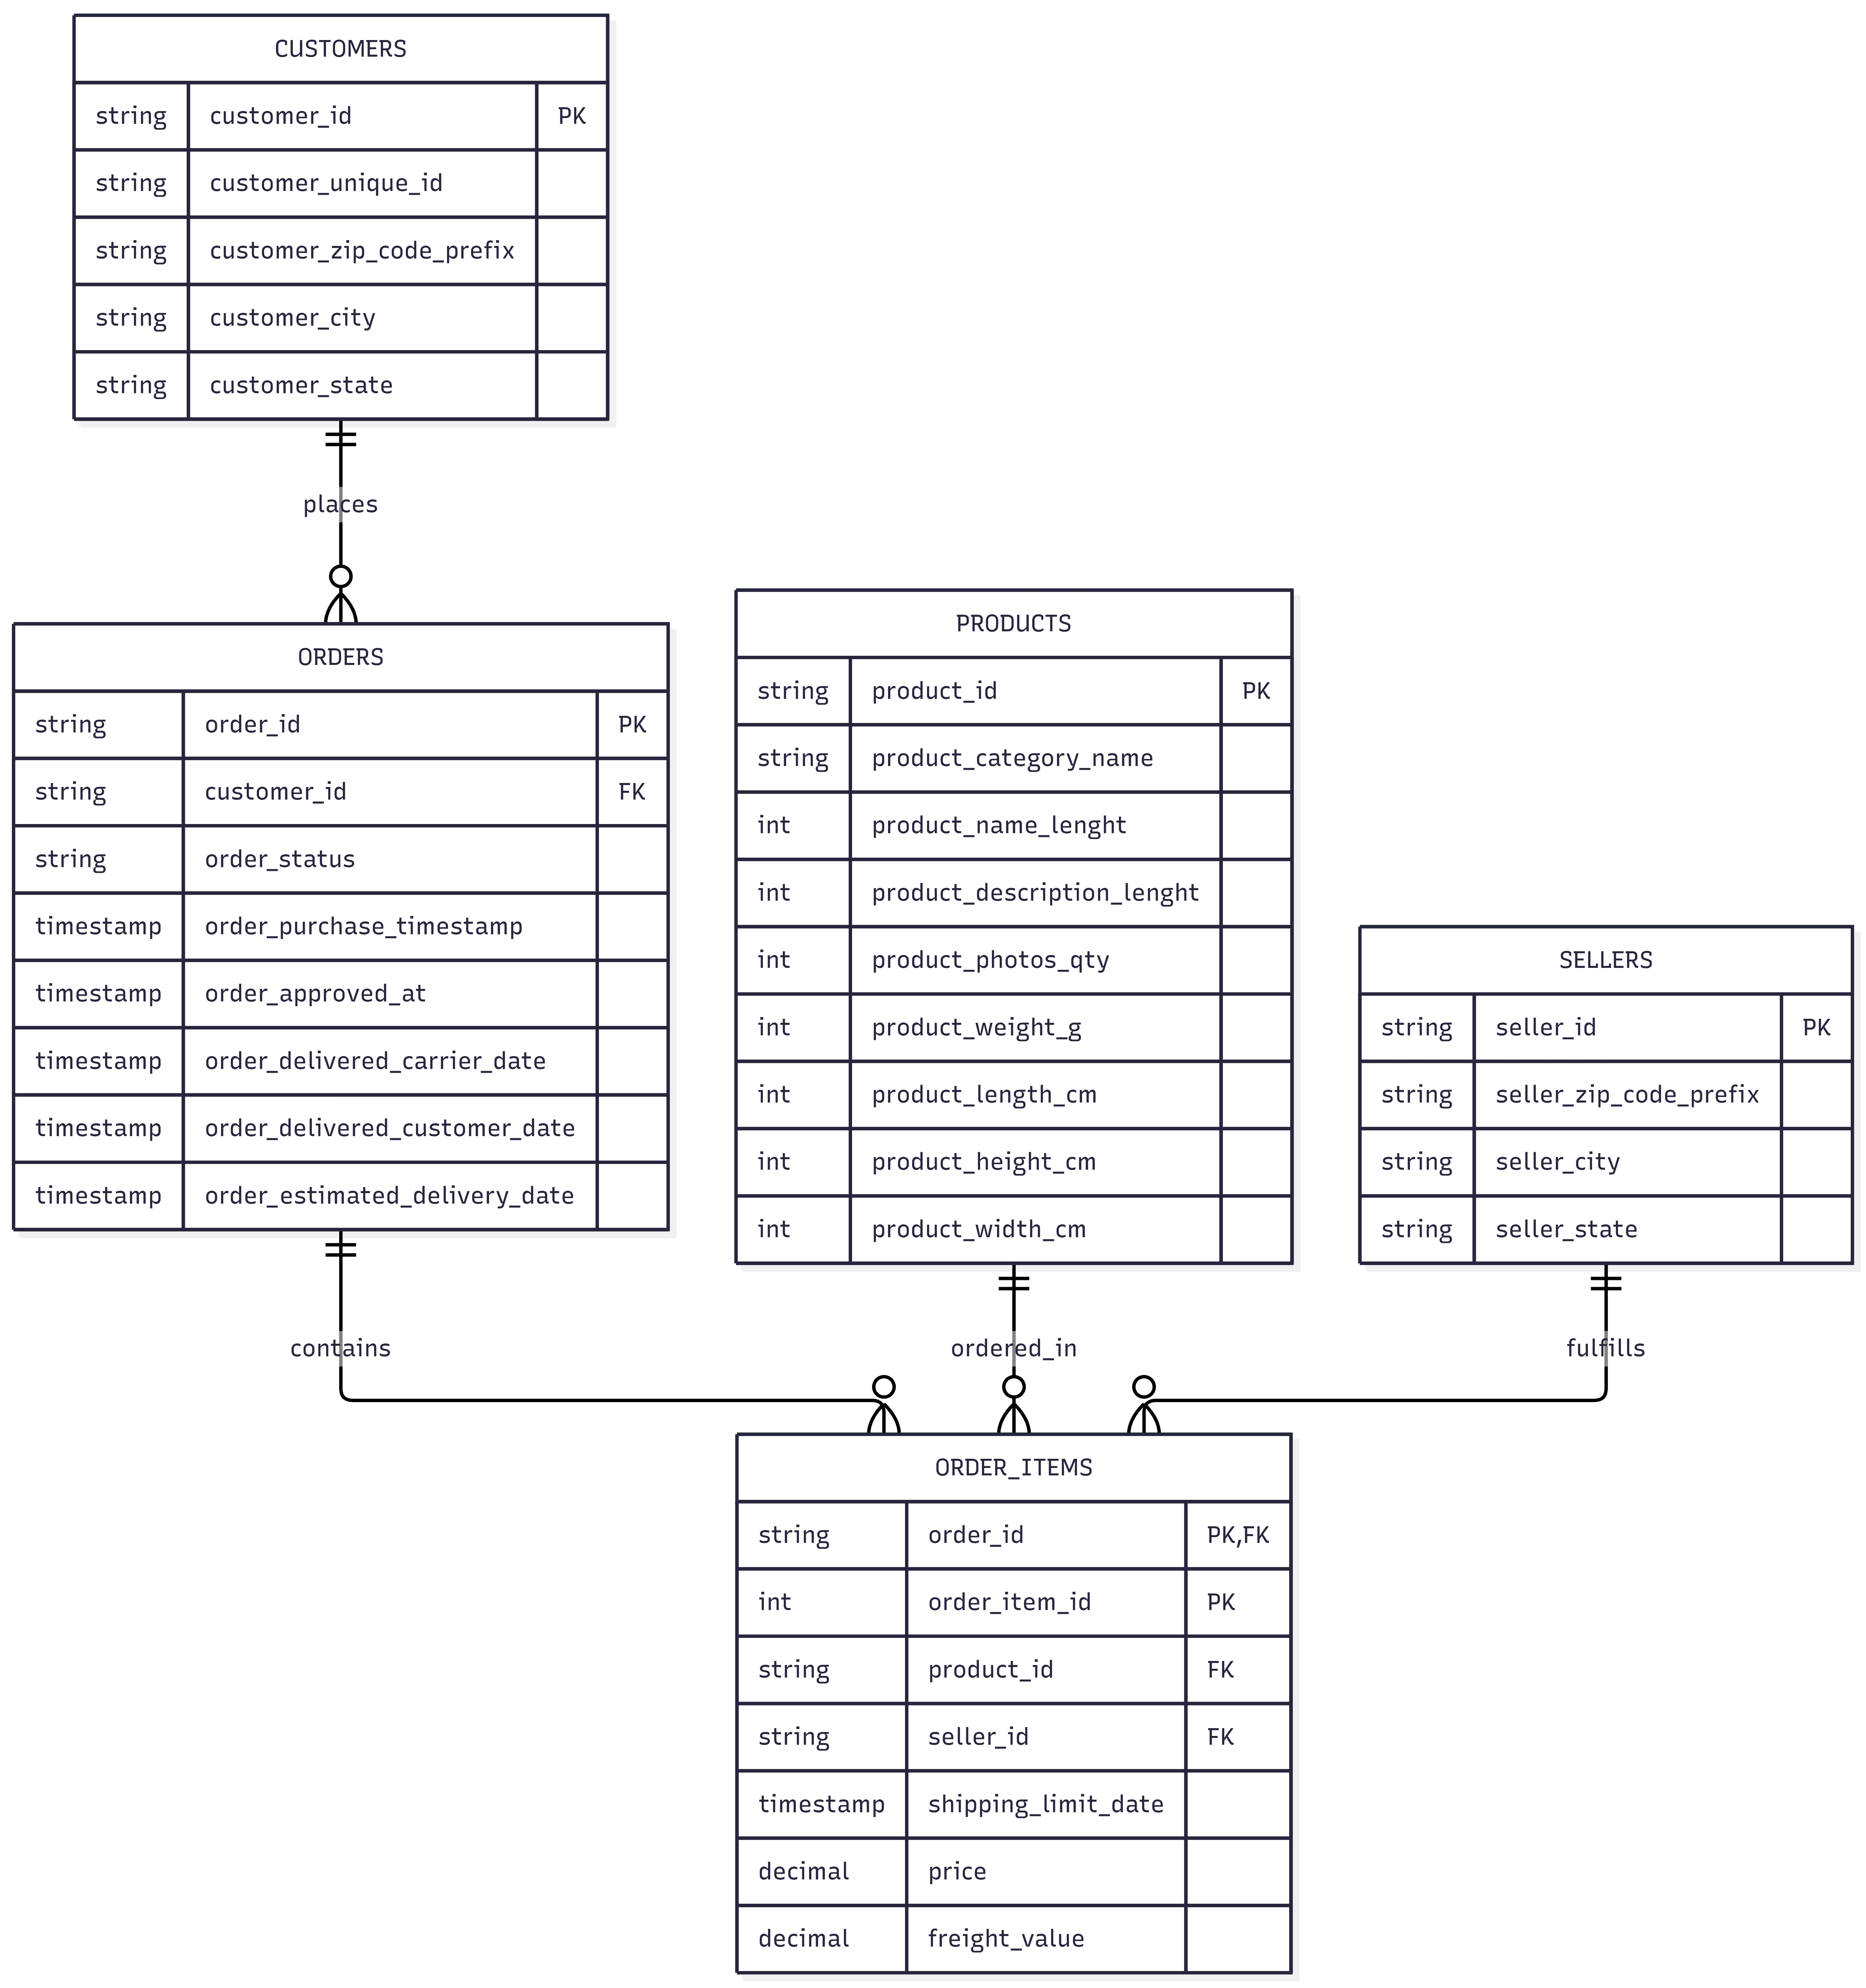

### Task 4: Short Note Summary

* **a. Customer Identifiers:** `customer_id` is a transient key generated uniquely for each individual order session. `customer_unique_id` represents the actual recurring physical person. To count distinct real-world customers, you must count `customer_unique_id`.
* **b. Junction Table:** `order_items` acts as the junction table, resolving the many-to-many relationship between `orders`, `products`, and `sellers`.
* **c. Data Strictness & Circle Justification:**
  * *Stricter Relationship:* The relationship from `orders` to `customers` is stricter than the diagram implies because the data contains zero orphan orders—every single order references a valid customer.
  * *Circle Justified:* The relationship from `orders` to `order_items` justifies a circle (zero-or-many) on the child side because 775 orders exist in the system without any associated order items.